In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix

sns.set_theme(style="whitegrid")

In [2]:
cols = [
    "pl_name", "hostname", "discoverymethod", "disc_year",
    "pl_orbper", "pl_orbsmax", "pl_rade", "pl_bmasse", "pl_eqt",
    "st_teff", "st_rad", "st_mass", "sy_dist", "sy_vmag",
]

query = "select " + ",".join(cols) + " from pscomppars"
url = (
    "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query="
    + query.replace(" ", "+")
    + "&format=csv"
)

try:
    raw = pd.read_csv(url)
    raw.to_csv("exoplanets_raw.csv", index=False)
except Exception as e:
    print("Download failed, trying the local copy:", e)
    raw = pd.read_csv("exoplanets_raw.csv")

print(raw.shape)
raw.head()

(6451, 14)


,pl_name,hostname,discoverymethod,disc_year,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,st_teff,st_rad,st_mass,sy_dist,sy_vmag
0,55 Cnc b,55 Cnc,Radial Velocity,1996,14.651552,0.11800,13.900,263.9785,700.00,5198.0,0.980,1.015,12.5855,5.95084
1,55 Cnc c,55 Cnc,Radial Velocity,2004,44.393600,0.24700,8.510,54.4738,499.27,5198.0,0.980,1.015,12.5855,5.95084
2,55 Cnc d,55 Cnc,Radial Velocity,2002,4799.000000,5.60000,13.000,1232.4930,104.85,5198.0,0.980,1.015,12.5855,5.95084
3,55 Cnc e,55 Cnc,Radial Velocity,2004,0.736547,0.01544,1.875,7.9900,1958.00,5172.0,0.943,0.905,12.5855,5.95084
4,55 Cnc f,55 Cnc,Radial Velocity,2007,260.580000,0.80200,7.590,44.8120,277.07,5198.0,0.980,1.015,12.5855,5.95084


In [3]:
print("Share of missing values per column:")
print(raw.isna().mean().round(2))
print("\n=====================================")
print("\nPlanets per discovery method:")
print(raw["discoverymethod"].value_counts())

Share of missing values per column:
pl_name            0.00
hostname           0.00
discoverymethod    0.00
disc_year          0.00
pl_orbper          0.05
pl_orbsmax         0.08
pl_rade            0.01
pl_bmasse          0.00
pl_eqt             0.08
st_teff            0.05
st_rad             0.05
st_mass            0.00
sy_dist            0.00
sy_vmag            0.05
dtype: float64


Planets per discovery method:
discoverymethod
Transit                          4785
Radial Velocity                  1204
Microlensing                      292
Imaging                            98
Transit Timing Variations          29
Eclipse Timing Variations          17
Orbital Brightness Modulation       9
Pulsar Timing                       8
Astrometry                          6
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64


## 1. How the catalog grew

Before looking at the planets themselves, it helps to see when and how they were found.

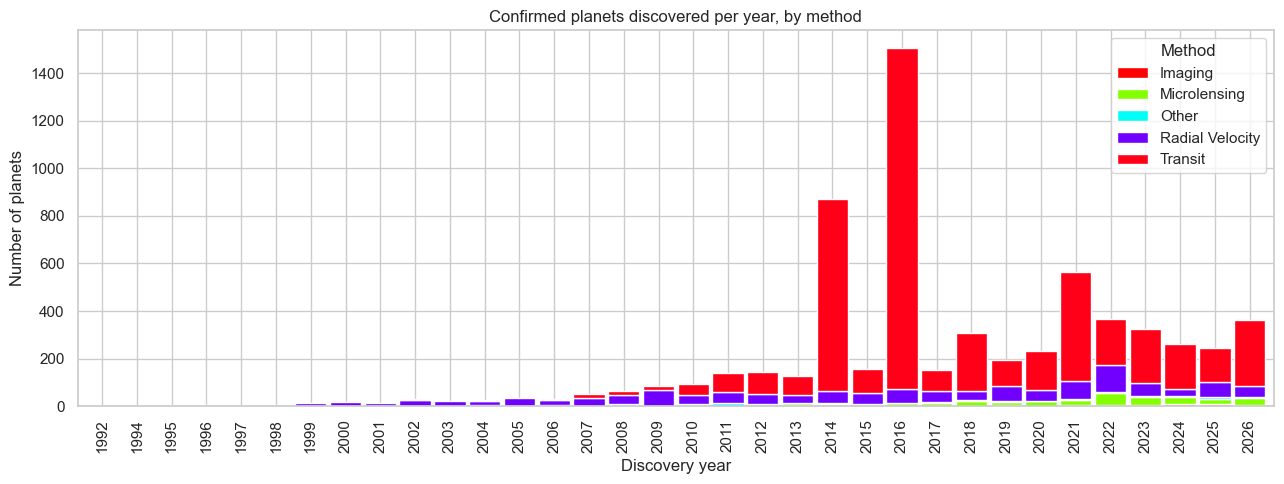

In [4]:
df = raw.copy()

top_methods = df["discoverymethod"].value_counts().head(4).index
df["method_group"] = np.where(
    df["discoverymethod"].isin(top_methods), df["discoverymethod"], "Other"
)

yearly = df.groupby(["disc_year", "method_group"]).size().unstack(fill_value=0)

yearly.plot(kind="bar", stacked=True, figsize=(13, 5), width=0.9, colormap="hsv")
plt.title("Confirmed planets discovered per year, by method")
plt.xlabel("Discovery year")
plt.ylabel("Number of planets")
plt.legend(title="Method")
plt.tight_layout()
plt.show()

## 2. Each method sees a different slice of the sky

If detection were unbiased, planets of every size and orbit would be scattered evenly 
across the period and radius plane. Let's see whether that is what we get.

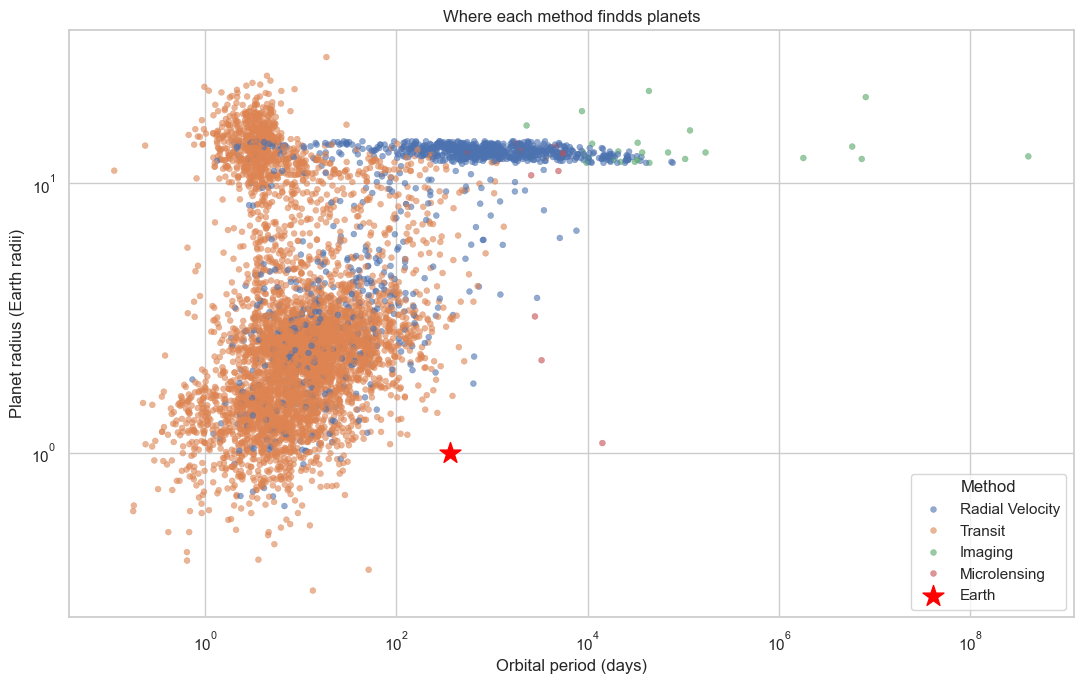

In [5]:
plot_df = df.dropna(subset=["pl_orbper", "pl_rade"])
plot_df = plot_df[plot_df["method_group"] != "Other"]

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=plot_df, x="pl_orbper", y="pl_rade",
    hue="method_group", alpha=0.6, s=18, edgecolor=None,
)
plt.xscale("log")
plt.yscale("log")
plt.scatter([365.25], [1.0], color="red", marker="*", s=250, label="Earth", zorder=5)
plt.xlabel("Orbital period (days)")
plt.ylabel("Planet radius (Earth radii)")
plt.title("Where each method findds planets")
plt.legend(title="Method")
plt.tight_layout()
plt.show()

## 3. Habitable zone candidates

Estimating each star's luminosity from its radius and temperature, then use the Kopparapu et al. (2013) polynomial fits to find the inner edge (runaway greenhouse) and outer edge (maximum greenhouse) of the habitable zone. A planet counts as a candidate if it sits between those edges and is small enough to plausibly be rocky (radius under 1.8 Earth radii).

In [6]:
runaway = (1.107, 1.332e-4, 1.58e-8, -8.308e-12, -1.931e-15)
maxgreen = (0.356, 6.171e-5, 1.698e-9, -3.198e-12, -5.575e-16)

def seff_limit(teff, coeffs):
    s0, a, b, c, d = coeffs
    t = teff - 5780.0
    return s0 + a * t + b * t**2 + c * t**3 + d * t**4

df["lum"] = df["st_rad"] ** 2 * (df["st_teff"] / 5772.0) ** 4

valid = df["st_teff"].between(2600, 7200)
teff_safe = df["st_teff"].where(valid)

df["hz_inner"] = np.sqrt(df["lum"] / seff_limit(teff_safe, runaway))
df["hz_outer"] = np.sqrt(df["lum"] / seff_limit(teff_safe, maxgreen))

a_kepler = (df["st_mass"] * (df["pl_orbper"] / 365.25) ** 2) ** (1 / 3)
df["a_au"] = df["pl_orbsmax"].fillna(a_kepler)

df["insolation"] = df["lum"] / df["a_au"] ** 2
df["in_hz"] = (df["a_au"] >= df["hz_inner"]) & (df["a_au"] <= df["hz_outer"])

candidates = df[df["in_hz"] & (df["pl_rade"] < 1.8)].sort_values("pl_rade")

print("Planets inside the habitable zone:", int(df["in_hz"].sum()))
print("Small (rocky-sized) candidates:", len(candidates))

candidates[
    ["pl_name", "discoverymethod", "pl_rade", "a_au", "hz_inner",
     "hz_outer", "st_teff", "sy_dist"]
].round(2).head(20)

Planets inside the habitable zone: 182
Small (rocky-sized) candidates: 18


,pl_name,discoverymethod,pl_rade,a_au,hz_inner,hz_outer,st_teff,sy_dist
1348,Proxima Cen b,Radial Velocity,1.02,0.05,0.04,0.07,2900.0,1.30
4168,Teegarden's Star c,Radial Velocity,1.02,0.05,0.03,0.07,3034.0,3.83
3479,GJ 1002 b,Radial Velocity,1.03,0.05,0.04,0.08,3024.0,4.85
949,Wolf 1069 b,Radial Velocity,1.08,0.07,0.06,0.11,3158.0,9.58
4956,GJ 1002 c,Radial Velocity,1.10,0.07,0.04,0.08,3024.0,4.85
143,TOI-700 d,Transit,1.14,0.16,0.15,0.30,3459.0,31.13
3603,GJ 1061 d,Radial Velocity,1.16,0.05,0.04,0.08,2953.0,3.67
1942,Kepler-186 f,Transit,1.17,0.43,0.23,0.44,3755.0,177.59
5842,GJ 3378 b,Radial Velocity,1.32,0.10,0.10,0.19,3340.0,7.72
917,Kepler-442 b,Transit,1.34,0.41,0.35,0.66,4402.0,365.96


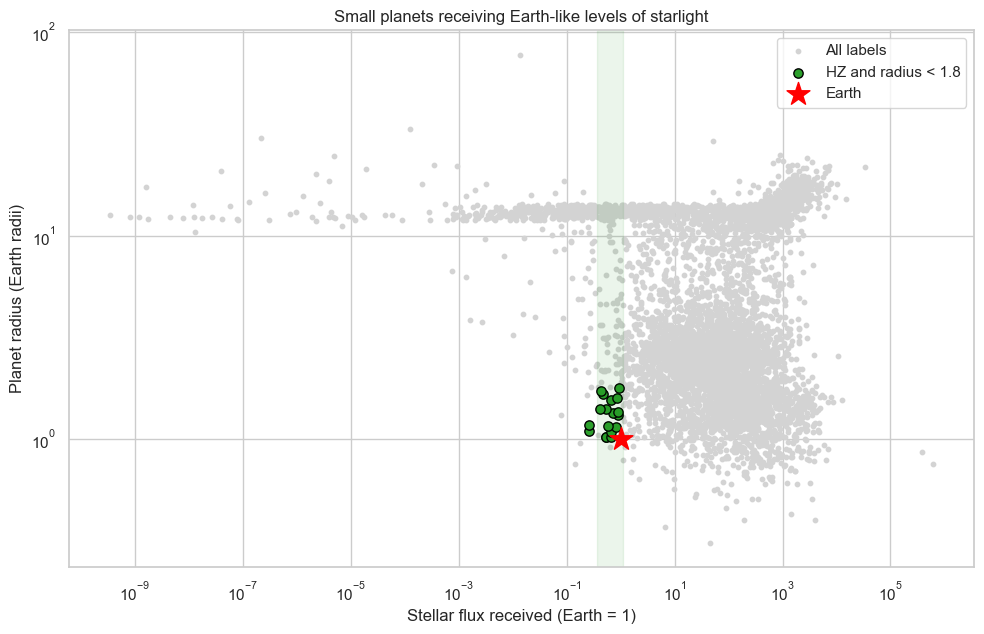

In [7]:
known = df.dropna(subset=["insolation", "pl_rade"])

plt.figure(figsize=(10, 6.5))
plt.scatter(known["insolation"], known["pl_rade"], s=10, color="lightgray", label="All labels")
plt.scatter(candidates["insolation"], candidates["pl_rade"], s=45,
            color="tab:green", edgecolor="black", label="HZ and radius < 1.8")
plt.scatter([1], [1], marker="*", s=300, color="red", label="Earth", zorder=5)

plt.axvspan(0.36, 1.1, color="green", alpha=0.08)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Stellar flux received (Earth = 1)")
plt.ylabel("Planet radius (Earth radii)")
plt.title("Small planets receiving Earth-like levels of starlight")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Correcting the transit bias

A planet only transits if its orbit is edge-on from our point of view. The chance of that alignment is roughly `R_star / a`. Close-in planets transit often, distant ones almost never. So each detected transiting planet really stands in for `1 / (R_star / a)` similar planets that we could not see. Weighting every planet by that factor gives a rough picture of the true distribution of periods.

This only fixes the geometry. It does not account for noise or how long a star was watched, so the corrected numbers are a better guide than the raw ones, not a final answer.

In [10]:
rsun_au = 0.00465047

tr = df[
    (df["discoverymethod"] == "Transit")
    & df["pl_orbper"].notna()
    & df["st_rad"].notna()
    & df["a_au"].notna()
    & (df["pl_rade"] < 4)
].copy()

tr["p_transit"] = (tr["st_rad"] * rsun_au / tr["a_au"]).clip(upper=1)
tr["weight"] = 1.0 / tr["p_transit"]

bins = np.logspace(np.log10(0.5), np.log10(500), 14)
tr["bin"] = pd.cut(tr["pl_orbper"], bins)

summary = tr.groupby("bin", observed=True).agg(
    observed=("pl_name", "count"),
    corrected=("weight", "sum"),
)
summary["observed_share"] = summary["observed"] / summary["observed"].sum()
summary["corrected_share"] = summary["corrected"] / summary["corrected"].sum()

summary[["observed", "observed_share", "corrected_share"]].round(3)

,observed,observed_share,corrected_share
bin,,,
"(0.5, 0.851]",76,0.021,0.003
"(0.851, 1.447]",112,0.032,0.006
"(1.447, 2.462]",200,0.057,0.017
"(2.462, 4.188]",428,0.121,0.048
"(4.188, 7.126]",619,0.175,0.094
"(7.126, 12.122]",643,0.182,0.133
"(12.122, 20.623]",616,0.174,0.178
"(20.623, 35.085]",377,0.107,0.149
"(35.085, 59.689]",242,0.068,0.134


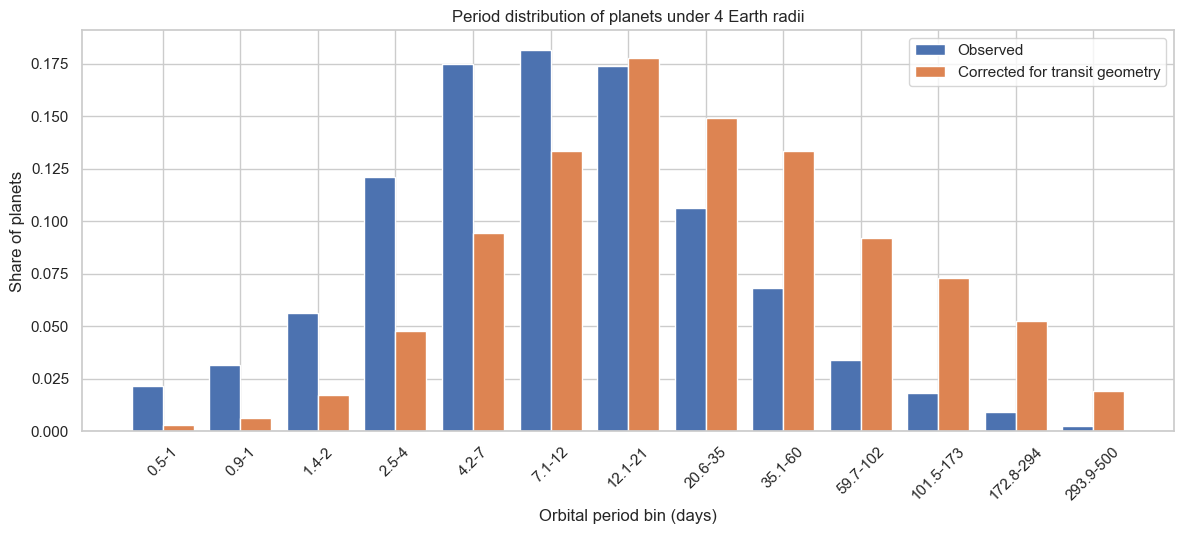

In [12]:
labels = [f"{iv.left:.1f}-{iv.right:.0f}" for iv in summary.index]
x = np.arange(len(labels))
width = 0.4

plt.figure(figsize=(12, 5.5))
plt.bar(x - width / 2, summary["observed_share"], width, label="Observed")
plt.bar(x + width / 2, summary["corrected_share"], width, label="Corrected for transit geometry")
plt.xticks(x, labels, rotation=45)
plt.xlabel("Orbital period bin (days)")
plt.ylabel("Share of planets")
plt.title("Period distribution of planets under 4 Earth radii")
plt.legend()
plt.tight_layout()
plt.show()